# Fase 0 · Etapa 0.3 — Métricas e função objetivo (C1, I15, N1)

> **Base de dados usada:** **dados do pesquisador** — `exp_5/Acrilico_engastado_livre_mponta_aponta.csv`
> (o caso do `main_otimizador.py`). Nenhuma base externa.

**Pergunta.** As funções objetivo que o legado entregava ao otimizador (`−MAC`, `−TSAC`,
`−RVAC`) conseguem, em princípio, identificar o amortecimento?

**Ideia física.** Uma função objetivo só identifica um parâmetro se ela **muda** quando o
parâmetro muda (sensibilidade ≠ 0). Se ela é constante, qualquer otimizador "para no
chute inicial" — não por mínimos locais, mas porque não há nada para minimizar.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

from dampid.audit import legacy_harness as lh

B = lh.load_legacy()
MAT, CC = "acrilico", "engastado_livre"
with lh.legacy_workdir():
    t, a, h = B.leitura_experimental(MAT, CC)
    out = B.pos_experimental(MAT, t, a, h, 6)
freq_frf, ampl_frf, amplitude, phi_exp = out[7], out[8], out[13], out[17]
print("phi_exp (o 'vetor modal experimental' do legado):", np.round(phi_exp, 2))
print("unidade: Hz — são as FREQUÊNCIAS dos picos, não formas modais")

phi_exp (o 'vetor modal experimental' do legado): [ 10.01  67.54 112.57 200.44 376.81]
unidade: Hz — são as FREQUÊNCIAS dos picos, não formas modais


## 1. C1 — o MAC do legado não depende de ζ
No legado, `phi_num = sqrt(autovalores de eigh(K, M))` [rad/s] e `phi_exp = frequências
dos picos` [Hz]. O MAC é calculado entre esses dois **vetores de frequências**. Como os
autovalores vêm do problema **sem amortecimento**, `phi_num` não muda com ζ.

In [2]:
zetas_test = [1e-7, 1e-5, 1e-3, 1e-2, 0.1, 0.5]
for z in zetas_test:
    _, _, _, phi_num = B.calculo_numerico_modal(MAT, CC, [z] * 6, 6, amplitude, 6, 0.01, 1e-4)
    print(f"ζ = {z:<7g} → MAC = {B.mac(phi_num, phi_exp):.15f}   phi_num[:3] = {np.round(phi_num[:3], 1)}")

ζ = 1e-07   → MAC = 0.980924058977776   phi_num[:3] = [ 107.   670.8 1747.3]
ζ = 1e-05   → MAC = 0.980924058977776   phi_num[:3] = [ 107.   670.8 1747.3]
ζ = 0.001   → MAC = 0.980924058977776   phi_num[:3] = [ 107.   670.8 1747.3]
ζ = 0.01    → MAC = 0.980924058977776   phi_num[:3] = [ 107.   670.8 1747.3]
ζ = 0.1     → MAC = 0.980924058977776   phi_num[:3] = [ 107.   670.8 1747.3]
ζ = 0.5     → MAC = 0.980924058977776   phi_num[:3] = [ 107.   670.8 1747.3]


**Confirmado (C1).** O MAC é idêntico até a 15ª casa decimal para ζ de 10⁻⁷ a 0,5. A
derivada da função objetivo é exatamente zero, e o L-BFGS-B "parou no chute inicial"
por isso (Tabela 4 da monografia).

Além disso, o número (≈0,98) **não tem significado físico**: o MAC é o cosseno² entre
dois vetores, e quaisquer duas listas crescentes de números positivos dão MAC alto.
Exemplo com listas sem relação nenhuma com a viga:

In [3]:
print("MAC([1,2,3,4,5], [10,30,31,80,200]) =", round(B.mac(np.array([1, 2, 3, 4, 5.]), np.array([10, 30, 31, 80, 200.])), 3))
print("MAC(phi_num, phi_exp*1000)          =", round(B.mac(phi_num, phi_exp * 1000), 15), "(invariante à escala)")

MAC([1,2,3,4,5], [10,30,31,80,200]) = 0.827
MAC(phi_num, phi_exp*1000)          = 0.980924058977776 (invariante à escala)


O MAC correto compara **formas modais** (amplitudes do mesmo modo em vários pontos da
estrutura) e serve para **parear modos**, não para identificar amortecimento
proporcional: os modos de um sistema com amortecimento proporcional são reais e
**independem** de ζ (Ewins, cap. 2).

## 2. RVAC — achado novo N1 (a função quebra) e sensibilidade a ζ
`frf_direta_modal_comparacao` cria os vetores de saída com tamanho fixo `n_freq = 4000`,
mas calcula só em `freq_experimental` (aqui, 1599 frequências). Sobram zeros no fim, e o
`rvac` recebe vetores de tamanhos diferentes:

In [4]:
_, _, _, a_num = B.frf_direta_modal_comparacao(CC, MAT, amplitude, freq_frf, [1e-6] * 6, 6)
print("len(freq_frf) =", len(freq_frf), "| len(a_num) =", len(a_num), "| não nulos =", np.count_nonzero(a_num))
try:
    B.rvac(np.abs(a_num) / 9810**2, ampl_frf)
except Exception as e:
    print("rvac FALHOU:", type(e).__name__, "-", str(e)[:90])

len(freq_frf) = 1599 | len(a_num) = 4000 | não nulos = 1598
rvac FALHOU: ValueError - matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,


**Confirmado (N1).** Com estes dados a métrica RVAC do `main_otimizador.py` quebra antes
do algoritmo genético rodar. (Ela só funcionaria se o espectro experimental tivesse
exatamente 4000 pontos abaixo de 500 Hz.)

Para examinar **o que o otimizador teria visto** se esse detalhe estivesse certo, a
célula abaixo recorta `a_num` no tamanho de `freq_frf` (é só isso; nenhuma outra
mudança) e varre ζ igual para todos os modos.

33 avaliações em 1.5 s
RVAC dentro dos limites do GA (ζ ≤ 1e-5): 0.12871 … 0.51691
RVAC máximo na varredura: 0.5647 em ζ_legado = 1.00e-04


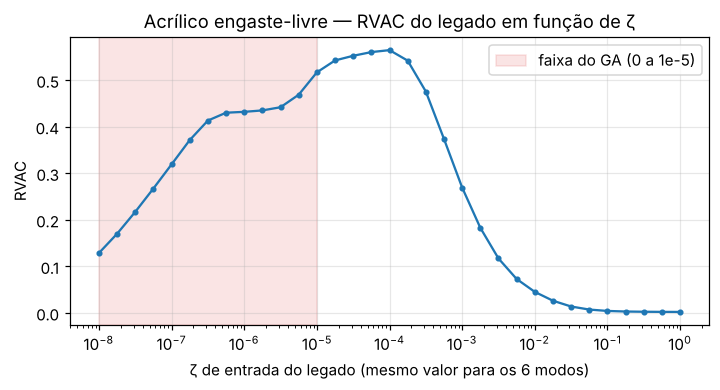

In [5]:
def rvac_trimmed(z):
    _, _, _, a = B.frf_direta_modal_comparacao(CC, MAT, amplitude, freq_frf, [z] * 6, 6)
    return B.rvac(np.abs(a[: len(freq_frf)]) / 9810**2, ampl_frf)

zgrid = np.logspace(-8, 0, 33)
t0 = time.time()
rv = np.array([rvac_trimmed(z) for z in zgrid])
print(f"{len(zgrid)} avaliações em {time.time() - t0:.1f} s")
ga_lo, ga_hi = 0.0, 1e-5
in_ga = (zgrid >= ga_lo) & (zgrid <= ga_hi)
print(f"RVAC dentro dos limites do GA (ζ ≤ 1e-5): {rv[in_ga].min():.5f} … {rv[in_ga].max():.5f}")
print(f"RVAC máximo na varredura: {rv.max():.4f} em ζ_legado = {zgrid[rv.argmax()]:.2e}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.semilogx(zgrid, rv, "o-", ms=3)
ax.axvspan(1e-8, 1e-5, color="tab:red", alpha=0.12, label="faixa do GA (0 a 1e-5)")
ax.set(xlabel="ζ de entrada do legado (mesmo valor para os 6 modos)", ylabel="RVAC",
       title="Acrílico engaste-livre — RVAC do legado em função de ζ")
ax.grid(alpha=0.3); ax.legend()

In [6]:
for z, v in zip(zgrid[::4], rv[::4]):
    print(f"ζ_legado = {z:8.1e}   RVAC = {v:.4f}")

ζ_legado =  1.0e-08   RVAC = 0.1287
ζ_legado =  1.0e-07   RVAC = 0.3192
ζ_legado =  1.0e-06   RVAC = 0.4321
ζ_legado =  1.0e-05   RVAC = 0.5169
ζ_legado =  1.0e-04   RVAC = 0.5647
ζ_legado =  1.0e-03   RVAC = 0.2694
ζ_legado =  1.0e-02   RVAC = 0.0454
ζ_legado =  1.0e-01   RVAC = 0.0044
ζ_legado =  1.0e+00   RVAC = 0.0023


**Leitura (diferente do que eu esperava).** A RVAC **varia** com ζ — ao contrário do MAC,
ela não é plana. Mas três coisas tornam a busca inútil:

1. **O ótimo da própria métrica fica fora dos limites do GA.** A RVAC cresce até
   ζ_legado ≈ 1e-4 e o GA só procura até 1e-5: o GA acabaria encostado no limite
   superior, e o "ζ ótimo" reportado seria o limite, não o ótimo.
2. **ζ_legado não é o ζ físico.** Pela construção errada de C (C2, notebook 03), o
   número que o GA ajusta não é a razão de amortecimento; o notebook 03 mostra a
   conversão.
3. **O melhor ajuste ainda é ruim (RVAC ≈ 0,56).** As frequências do modelo não batem
   com as medidas (C7/C8, notebooks 05 e 07), então nenhum ζ consegue sobrepor os picos.

A busca em si também é minúscula (I15: população 8 × 20 gerações ≈ 170 avaliações em
6 dimensões).

Observação: RVAC e TSAC são **invariantes à escala** (multiplicar a FRF numérica por
qualquer constante não muda a métrica). Por isso os fatores 9,81 / 9810 / 9810² do
legado (C5) nunca apareciam como erro.

In [7]:
print("RVAC(a) =", round(rvac_trimmed(1e-3), 6), "| RVAC(1000·a) =",
      round(float(B.rvac(1000 * np.abs(B.frf_direta_modal_comparacao(CC, MAT, amplitude, freq_frf, [1e-3] * 6, 6)[3][:len(freq_frf)]) / 9810**2, ampl_frf)), 6))

RVAC(a) = 0.269435 | RVAC(1000·a) = 0.269435


## 3. I15 — configuração do algoritmo genético
Lida diretamente do `main_otimizador.py`: `var_bound = (0, 1e-5)` por modo,
`population_size = 8`, `max_num_iteration = 20`. O GA não pôde ser executado aqui
(`geneticalgorithm2` não instalável no ambiente, e a métrica quebra antes — N1), mas a
configuração por si só confirma o item: busca em 6 dimensões com ≈170 avaliações numa
faixa que exclui o ótimo da própria métrica.

## Resumo da etapa
| Item | Status | Evidência |
|---|---|---|
| C1 | **confirmado** | MAC idêntico (15 casas) para ζ ∈ [1e-7, 0,5]; MAC alto para listas sem relação |
| N1 (novo) | **confirmado** | `rvac` quebra: vetores de 4000 × 1599 pontos |
| I15 | **confirmado** (estático + varredura) | limites (0, 1e-5), 8 × 20; ótimo da RVAC em ζ_legado ≈ 1e-4, fora da faixa |